# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Firas Razin
- **Email:** firasrazin2006@gmail.com
- **ID Dicoding:** -

## Menentukan Pertanyaan Bisnis

Konteks: operator sistem bike sharing (Capital Bikeshare, Washington D.C.) ingin mengatur penempatan sepeda, jadwal perawatan, dan strategi promosi berdasarkan pola penyewaan tahun 2011–2012.

1. **Pada jam berapa puncak rata-rata penyewaan sepeda per jam terjadi pada hari kerja dibandingkan hari non-kerja (akhir pekan/libur) sepanjang tahun 2012, dan berapa selisih rata-rata penyewaan antara jam puncak dan jam tersepi di masing-masing tipe hari?** 
   *(Specific: jam & tipe hari; Measurable: rata-rata penyewaan/jam; Action: jadwal redistribusi sepeda & perawatan; Relevant: ketersediaan armada; Time-bound: 2012)*
2. **Berapa persen rata-rata penyewaan harian turun pada cuaca hujan/salju ringan dan cuaca berkabut dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah selama 2011–2012?** 
   *(Specific: kondisi cuaca & musim; Measurable: % penurunan & rata-rata harian; Action: promosi musiman & perencanaan armada; Relevant: faktor lingkungan; Time-bound: 2011–2012)*
3. **Berapa pertumbuhan total penyewaan sepeda tiap bulan pada 2012 dibandingkan bulan yang sama di 2011 (Year-over-Year), dan berapa proporsi pengguna terdaftar (registered) terhadap pengguna kasual pada kedua tahun?** 
   *(Specific: pertumbuhan bulanan & tipe pengguna; Measurable: % YoY & proporsi; Action: fokus akuisisi/retensi pengguna; Relevant: pertumbuhan bisnis; Time-bound: 2011 vs 2012)*

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Data Wrangling

### Gathering Data

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("day.csv  :", day_df.shape)
print("hour.csv :", hour_df.shape)
day_df.head()

day.csv  : (731, 16)
hour.csv : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi 731 baris (agregasi harian, 2011–2012) dan `hour.csv` berisi 17.379 baris (agregasi per jam).
- Kedua tabel memiliki kolom yang sama, kecuali `hr` yang hanya ada di `hour.csv`. Kolom kategorikal (season, weathersit, dll.) masih berupa kode angka dan suhu/kelembapan/angin masih ternormalisasi.

### Assessing Data

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name} ===")
    df.info()
    print("Missing value  :", df.isna().sum().sum())
    print("Duplikat       :", df.duplicated().sum())
    print()

=== day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
Missing value  : 0
Duplikat       : 0

=== hour_df ===
<class 'pandas.DataFrame'>
RangeIndex:

**Temuan 1 – Tipe data tidak sesuai:** `dteday` bertipe string (object), seharusnya datetime.

In [5]:
print("Contoh hum = 0 pada day_df:")
print(day_df[day_df["hum"] == 0][["dteday", "hum", "temp", "weathersit", "cnt"]])
print("\nJumlah baris hum = 0 pada hour_df:", (hour_df["hum"] == 0).sum())
print("Tanggal-nya:", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

Contoh hum = 0 pada day_df:
        dteday  hum      temp  weathersit  cnt
68  2011-03-10  0.0  0.389091           3  623

Jumlah baris hum = 0 pada hour_df: 22
Tanggal-nya: <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


**Temuan 2 – Invalid value:** kelembapan (`hum`) bernilai 0 pada 2011-03-10 (1 baris di `day_df`, 22 baris di `hour_df`). Kelembapan 0% tidak masuk akal secara fisik, ini kemungkinan sensor/data hilang yang dikodekan sebagai 0.

In [6]:
# Kelengkapan data per jam
expected_hours = len(pd.date_range("2011-01-01", "2012-12-31 23:00", freq="h"))
print("Jam seharusnya :", expected_hours)
print("Jam tercatat   :", len(hour_df))
print("Jam hilang     :", expected_hours - len(hour_df))
print()
print("Distribusi weathersit (hour_df):")
print(hour_df["weathersit"].value_counts().sort_index())
print("\nDistribusi weathersit (day_df):")
print(day_df["weathersit"].value_counts().sort_index())

Jam seharusnya : 17544
Jam tercatat   : 17379
Jam hilang     : 165

Distribusi weathersit (hour_df):
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

Distribusi weathersit (day_df):
weathersit
1    463
2    247
3     21
Name: count, dtype: int64


**Temuan 3 – Data tidak lengkap:** `hour_df` hanya memiliki 17.379 dari 17.544 jam yang seharusnya (165 jam hilang, umumnya jam tanpa transaksi). Konsekuensinya, total harian **tidak boleh dihitung dari `hour_df`**; total harian dipakai dari `day_df`, sedangkan `hour_df` hanya dipakai untuk rata-rata per jam.

**Temuan 4 – Kategori sangat jarang:** `weathersit = 4` (hujan lebat/salju) hanya 3 baris di `hour_df` dan tidak ada di `day_df`, sehingga tidak dapat dibandingkan secara andal.

In [7]:
# Deteksi outlier dengan IQR pada day_df
def outlier_summary(df, cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({"kolom": c, "batas_bawah": lo, "batas_atas": hi,
                     "jumlah_outlier": ((df[c] < lo) | (df[c] > hi)).sum()})
    return pd.DataFrame(rows)

outlier_summary(day_df, ["cnt", "casual", "registered", "windspeed", "hum", "temp"])

,kolom,batas_bawah,batas_atas,jumlah_outlier
0,cnt,-1054.000000,10162.000000,0
1,casual,-855.250000,2266.750000,44
2,registered,-922.250000,8195.750000,0
3,windspeed,-0.012447,0.380611,13
4,hum,0.204687,1.045521,2
5,temp,-0.140416,1.132916,0


In [8]:
# Validasi konsistensi
print("cnt != casual + registered (day) :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())
print("cnt != casual + registered (hour):", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())
print("workingday=1 sekaligus holiday=1 :", ((day_df["workingday"] == 1) & (day_df["holiday"] == 1)).sum())
d = pd.to_datetime(day_df["dteday"])
print("weekday tidak cocok dengan tanggal:", ((d.dt.dayofweek + 1) % 7 != day_df["weekday"]).sum())

cnt != casual + registered (day) : 0
cnt != casual + registered (hour): 0
workingday=1 sekaligus holiday=1 : 0
weekday tidak cocok dengan tanggal: 0


**Temuan 5 – Outlier:** `casual` (44 hari) dan `windspeed` (13 hari) memiliki outlier menurut IQR. Setelah diperiksa, nilai-nilai ini merupakan lonjakan pengguna kasual yang wajar (hari libur/cuaca baik) dan hari berangin, bukan kesalahan input. Total `cnt` tidak memiliki outlier. Kolom lain konsisten (casual + registered = cnt, tidak ada konflik workingday/holiday).

**Rencana Cleaning:**
1. Ubah `dteday` menjadi datetime.
2. Ganti `hum = 0` menjadi NaN, lalu isi dengan median kelembapan (tanpa nilai 0) pada bulan dan tahun yang sama.
3. Ubah kode kategorikal menjadi label deskriptif (musim, tahun, cuaca, hari) dan buat kolom suhu dalam °C, tipe hari (Hari Kerja / Non-Kerja).
4. Outlier **dipertahankan** (valid secara bisnis); analisis memakai rata-rata dan membandingkan dengan median bila perlu.
5. Jam yang hilang **tidak diimputasi** karena analisis memakai rata-rata per jam.
6. `weathersit = 4` dipertahankan di `hour_df` namun dicatat sebagai sampel sangat kecil.

### Cleaning Data

In [9]:
season_map = {1: "Semi", 2: "Panas", 3: "Gugur", 4: "Dingin"}
weather_map = {1: "Cerah", 2: "Berkabut", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

def clean(df):
    df = df.copy()
    # 1. tipe data
    df["dteday"] = pd.to_datetime(df["dteday"])
    # 2. invalid value hum = 0 -> median bulan & tahun yang sama
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].fillna(df.groupby(["yr", "mnth"])["hum"].transform("median"))
    # 3. label & fitur turunan
    df["season_label"] = df["season"].map(season_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["month_label"] = df["mnth"].apply(lambda m: month_names[m - 1])
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Non-Kerja")
    df["temp_c"] = df["temp"] * 41
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67
    return df

day_clean = clean(day_df)
hour_clean = clean(hour_df)

print("hum = 0 tersisa  -> day:", (day_clean["hum"] == 0).sum(), "| hour:", (hour_clean["hum"] == 0).sum())
print("Missing value    -> day:", day_clean["hum"].isna().sum(), "| hour:", hour_clean["hum"].isna().sum())
print("Nilai hum 2011-03-10 setelah diimputasi:", day_clean.loc[day_clean["dteday"] == "2011-03-10", "hum"].round(3).values)
day_clean.head()

hum = 0 tersisa  -> day: 0 | hour: 0
Missing value    -> day: 0 | hour: 0
Nilai hum 2011-03-10 setelah diimputasi: [0.573]


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,cnt,season_label,year,month_label,weather_label,weekday_label,day_type,temp_c,hum_pct,windspeed_kmh
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,985,Semi,2011,Jan,Berkabut,Sabtu,Non-Kerja,14.110847,80.5833,10.749882
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,801,Semi,2011,Jan,Berkabut,Minggu,Non-Kerja,14.902598,69.6087,16.652113
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,1349,Semi,2011,Jan,Cerah,Senin,Hari Kerja,8.050924,43.7273,16.636703
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,...,1562,Semi,2011,Jan,Cerah,Selasa,Hari Kerja,8.200000,59.0435,10.739832
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,...,1600,Semi,2011,Jan,Cerah,Rabu,Hari Kerja,9.305237,43.6957,12.522300


In [10]:
# Simpan data bersih untuk dashboard
day_clean.to_csv("dashboard/main_data.csv", index=False)
hour_clean.to_csv("dashboard/hour_clean.csv", index=False)
print("Tersimpan: dashboard/main_data.csv & dashboard/hour_clean.csv")

Tersimpan: dashboard/main_data.csv & dashboard/hour_clean.csv


**Insight:**
- `dteday` kini bertipe datetime, nilai `hum = 0` sudah diimputasi dengan median bulan-tahun yang sama, dan seluruh kode kategorikal sudah memiliki label yang mudah dibaca.
- `day_clean` disimpan sebagai `main_data.csv` (sumber data dashboard) dan `hour_clean` sebagai `hour_clean.csv`.

## Exploratory Data Analysis (EDA)

### Eksplorasi Data Umum

In [11]:
day_clean[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(2)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,4504.35,848.18,3656.17,20.31,62.87,12.76
std,1937.21,686.62,1560.26,7.51,14.05,5.19
min,22.00,2.00,20.00,2.42,18.79,1.50
25%,3152.00,315.50,2497.00,13.82,52.10,9.04
50%,4548.00,713.00,3662.00,20.43,62.67,12.13
75%,5956.00,1096.00,4776.50,26.87,73.02,15.63
max,8714.00,3410.00,6946.00,35.33,97.25,34.00


In [12]:
print("Total penyewaan per tahun:")
print(day_clean.groupby("year")[["casual", "registered", "cnt"]].sum())
print("\nKorelasi dengan cnt (harian):")
print(day_clean[["cnt", "temp_c", "hum_pct", "windspeed_kmh"]].corr()["cnt"].round(3))

Total penyewaan per tahun:
      casual  registered      cnt
year                             
2011  247252      995851  1243103
2012  372765     1676811  2049576

Korelasi dengan cnt (harian):
cnt              1.000
temp_c           0.627
hum_pct         -0.113
windspeed_kmh   -0.235
Name: cnt, dtype: float64


**Insight:**
- Rata-rata penyewaan harian sekitar 4.500 sepeda (min 22, maks 8.714).
- Suhu berkorelasi positif kuat dengan penyewaan (≈ 0,63), sedangkan kelembapan dan kecepatan angin berkorelasi negatif lemah.

### Pertanyaan 1: Pola penyewaan per jam, hari kerja vs non-kerja (2012)

In [13]:
h12 = hour_clean[hour_clean["year"] == 2012]
hourly = h12.groupby(["day_type", "hr"])["cnt"].mean().unstack(0).round(1)

summary_q1 = pd.DataFrame({
    "Jam puncak": hourly.idxmax(),
    "Rata-rata di jam puncak": hourly.max(),
    "Jam tersepi": hourly.idxmin(),
    "Rata-rata di jam tersepi": hourly.min(),
})
summary_q1["Selisih puncak - tersepi"] = summary_q1["Rata-rata di jam puncak"] - summary_q1["Rata-rata di jam tersepi"]
print(summary_q1)

print("\nRata-rata per jam keseluruhan:")
print(h12.groupby("day_type")["cnt"].mean().round(1))
print("\n3 jam tersibuk pada Hari Kerja :", hourly["Hari Kerja"].nlargest(3).round(0).to_dict())
print("3 jam tersibuk pada Non-Kerja  :", hourly["Non-Kerja"].nlargest(3).round(0).to_dict())

            Jam puncak  Rata-rata di jam puncak  Jam tersepi  \
day_type                                                       
Hari Kerja          17                    656.2            3   
Non-Kerja           13                    458.9            4   

            Rata-rata di jam tersepi  Selisih puncak - tersepi  
day_type                                                        
Hari Kerja                       5.5                     650.7  
Non-Kerja                        9.9                     449.0  

Rata-rata per jam keseluruhan:
day_type
Hari Kerja    241.2
Non-Kerja     220.7
Name: cnt, dtype: float64

3 jam tersibuk pada Hari Kerja : {17: 656.0, 18: 617.0, 8: 604.0}
3 jam tersibuk pada Non-Kerja  : {13: 459.0, 12: 451.0, 14: 448.0}


### Pertanyaan 2: Pengaruh cuaca dan musim terhadap penyewaan harian (2011–2012)

In [14]:
weather = (day_clean.groupby("weather_label")["cnt"]
           .agg(rata_rata="mean", median="median", jumlah_hari="count").round(0))
base = weather.loc["Cerah", "rata_rata"]
weather["penurunan_vs_cerah_%"] = ((1 - weather["rata_rata"] / base) * 100).round(1)
print(weather)

season = (day_clean.groupby("season_label")["cnt"]
          .agg(rata_rata="mean", median="median", jumlah_hari="count").round(0)
          .sort_values("rata_rata", ascending=False))
print()
print(season)
print("\nSelisih musim tertinggi vs terendah: %.1f%%" %
      ((1 - season["rata_rata"].min() / season["rata_rata"].max()) * 100))

                    rata_rata  median  jumlah_hari  penurunan_vs_cerah_%
weather_label                                                           
Berkabut               4036.0  4040.0          247                  17.2
Cerah                  4877.0  4844.0          463                   0.0
Hujan/Salju Ringan     1803.0  1817.0           21                  63.0

              rata_rata  median  jumlah_hari
season_label                                
Gugur            5644.0  5354.0          188
Panas            4992.0  4942.0          184
Dingin           4728.0  4634.0          178
Semi             2604.0  2209.0          181

Selisih musim tertinggi vs terendah: 53.9%


In [15]:
# Kontrol: apakah efek cuaca konsisten di setiap musim?
pd.crosstab(day_clean["season_label"], day_clean["weather_label"],
            values=day_clean["cnt"], aggfunc="mean").round(0)

weather_label,Berkabut,Cerah,Hujan/Salju Ringan
season_label,,,
Dingin,4654.0,5044.0,1962.0
Gugur,5222.0,5878.0,2752.0
Panas,4237.0,5549.0,1169.0
Semi,2357.0,2811.0,935.0


### Pertanyaan 3: Pertumbuhan YoY bulanan dan proporsi tipe pengguna

In [16]:
monthly = day_clean.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
monthly["yoy_%"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly.index = month_names
print(monthly)

tot = day_clean.groupby("year")[["casual", "registered", "cnt"]].sum()
tot["registered_%"] = (tot["registered"] / tot["cnt"] * 100).round(1)
tot["casual_%"] = (tot["casual"] / tot["cnt"] * 100).round(1)
print()
print(tot)
print("\nPertumbuhan total 2012 vs 2011: %.1f%%" % ((tot.loc[2012, "cnt"] / tot.loc[2011, "cnt"] - 1) * 100))
print("Pertumbuhan registered: %.1f%% | casual: %.1f%%" % (
    (tot.loc[2012, "registered"] / tot.loc[2011, "registered"] - 1) * 100,
    (tot.loc[2012, "casual"] / tot.loc[2011, "casual"] - 1) * 100))

year    2011    2012  yoy_%
Jan    38189   96744  153.3
Feb    48215  103137  113.9
Mar    64045  164875  157.4
Apr    94870  174224   83.6
Mei   135821  195865   44.2
Jun   143512  202830   41.3
Jul   141341  203607   44.1
Agu   136691  214503   56.9
Sep   127418  218573   71.5
Okt   123511  198841   61.0
Nov   102167  152664   49.4
Des    87323  123713   41.7

      casual  registered      cnt  registered_%  casual_%
year                                                     
2011  247252      995851  1243103          80.1      19.9
2012  372765     1676811  2049576          81.8      18.2

Pertumbuhan total 2012 vs 2011: 64.9%
Pertumbuhan registered: 68.4% | casual: 50.8%


**Insight EDA:**
- Hari kerja memiliki dua puncak (pukul 08:00 dan 17:00), sedangkan hari non-kerja memiliki satu puncak landai di tengah hari (≈ 13:00).
- Penyewaan turun drastis saat hujan/salju ringan, dan musim gugur adalah musim tersibuk.
- Pertumbuhan YoY sangat tinggi di awal tahun dan melambat di paruh kedua tahun; pengguna terdaftar mendominasi (~80%).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan terjadi di hari kerja vs non-kerja (2012)?

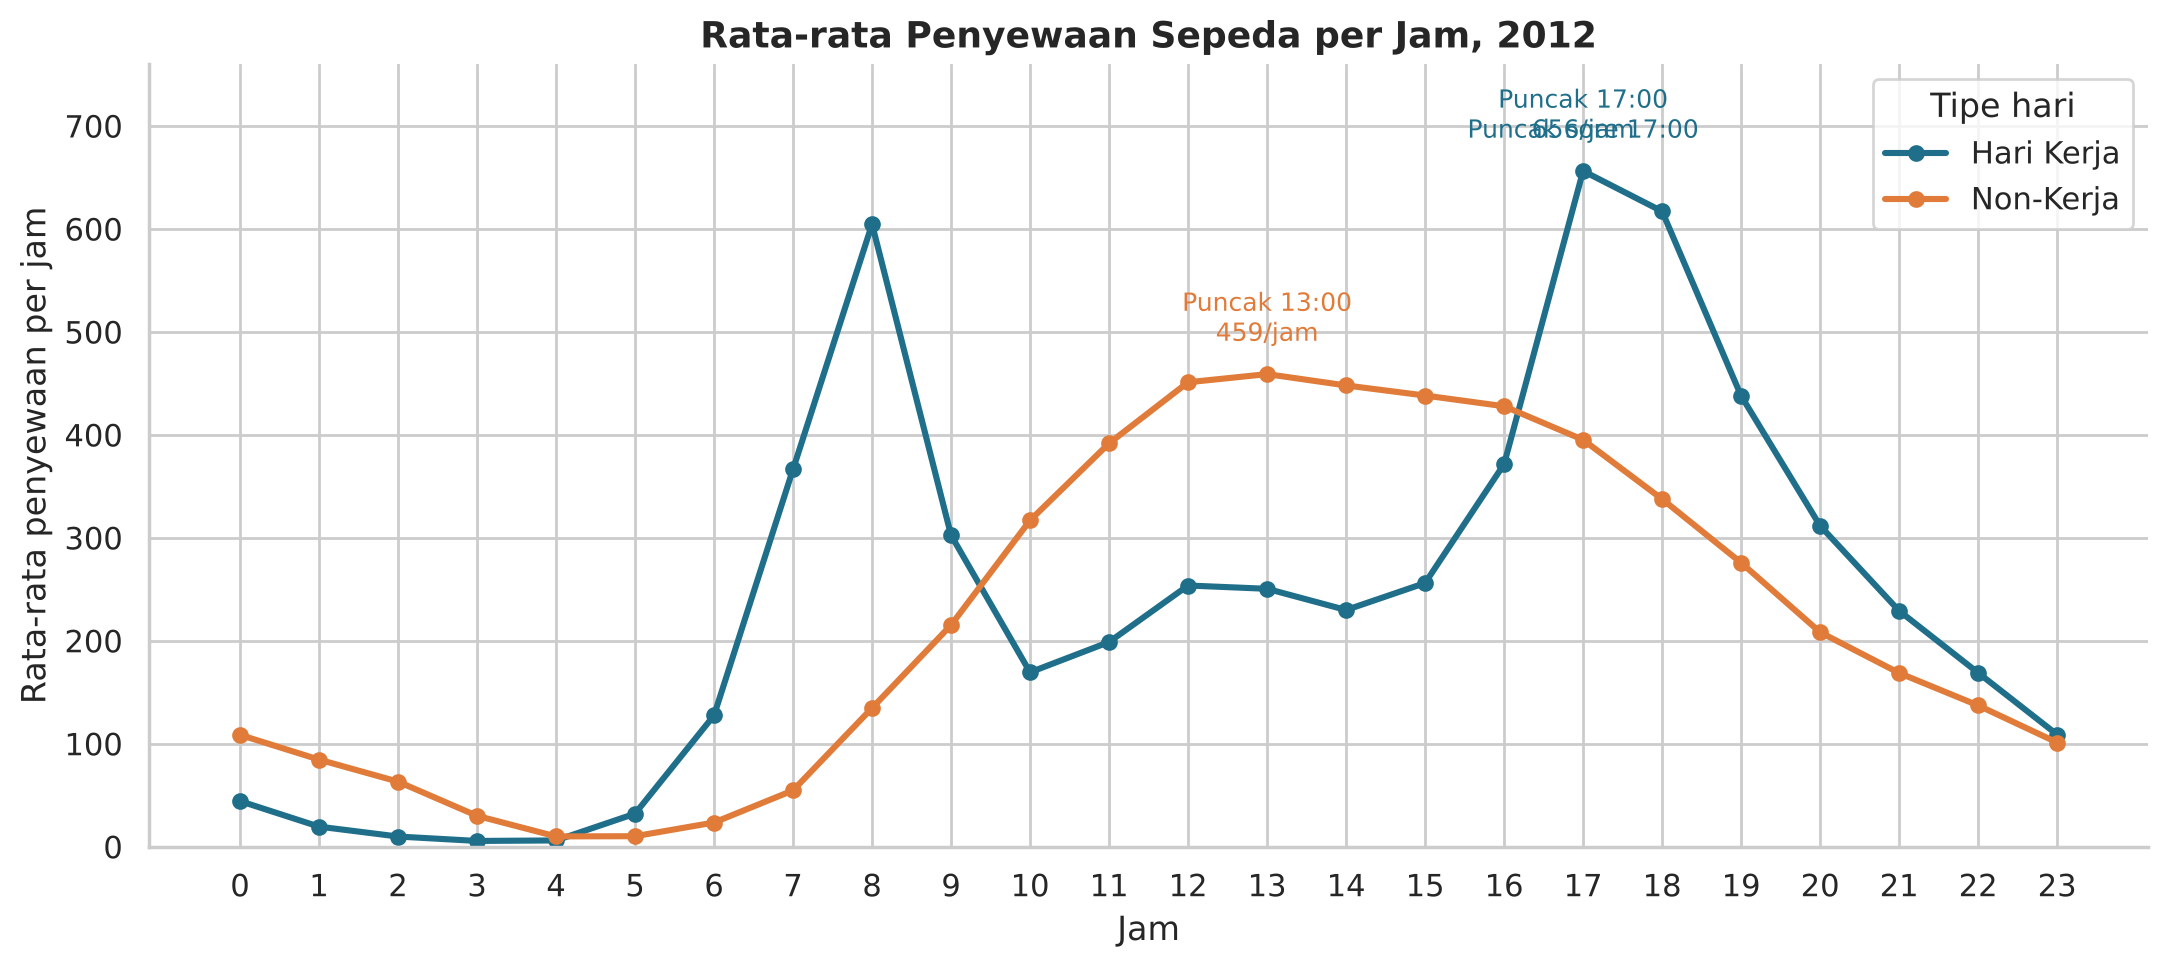

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"Hari Kerja": "#1f6f8b", "Non-Kerja": "#e07b39"}
for col in hourly.columns:
    ax.plot(hourly.index, hourly[col], marker="o", lw=2.2, ms=5, label=col, color=colors[col])
    pk = hourly[col].idxmax()
    ax.annotate(f"Puncak {pk:02d}:00\n{hourly[col].max():.0f}/jam", (pk, hourly[col].max()),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9, color=colors[col])
ax.annotate("Puncak sore 17:00", (17, hourly["Hari Kerja"].loc[17]), textcoords="offset points",
            xytext=(0, 12), ha="center", fontsize=9, color=colors["Hari Kerja"])
ax.set_xticks(range(0, 24))
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Rata-rata Penyewaan Sepeda per Jam, 2012", fontsize=13, weight="bold")
ax.set_ylim(0, 760)
ax.legend(title="Tipe hari")
sns.despine()
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 1**
- **Hari kerja** punya pola komuter: puncak utama pukul **17:00 (≈ 656 sepeda/jam)** dan puncak kedua pukul **08:00 (≈ 605/jam)**. Jam tersepi pukul 03:00 (≈ 5/jam), selisih puncak–tersepi ≈ **651 sepeda/jam**.
- **Hari non-kerja** punya pola rekreasi: satu puncak landai pukul **13:00 (≈ 459/jam)** dengan jam tersepi pukul 04:00–05:00 (≈ 10/jam), selisih ≈ **449 sepeda/jam**.
- Implikasi: kebutuhan armada pada hari kerja sangat terkonsentrasi pada dua jendela sempit sehingga rawan kekosongan/penuh stasiun.

### Pertanyaan 2: Seberapa besar cuaca dan musim memengaruhi penyewaan harian?

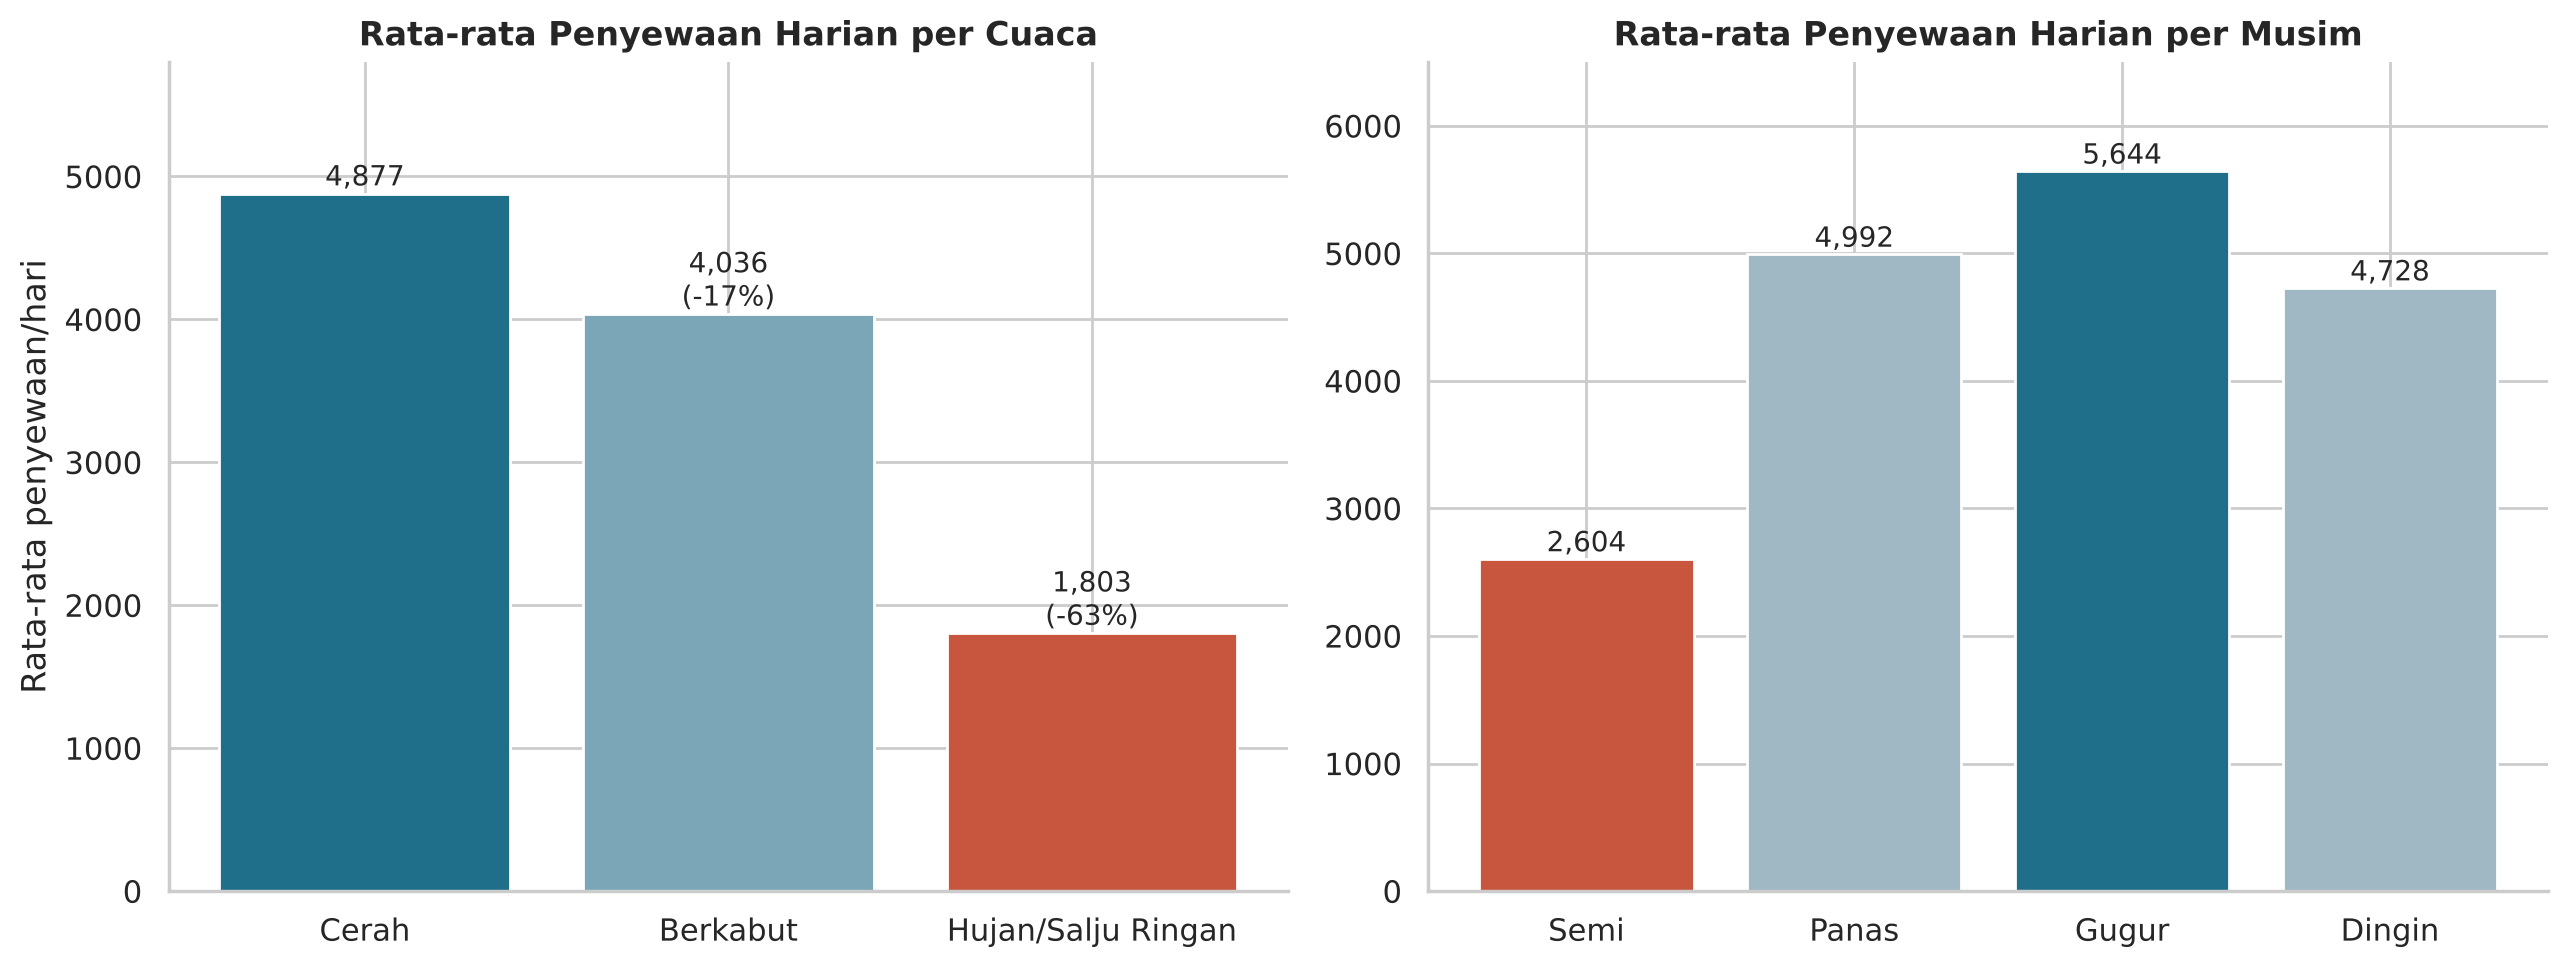

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order_w = ["Cerah", "Berkabut", "Hujan/Salju Ringan"]
w = weather.loc[order_w]
bars = axes[0].bar(order_w, w["rata_rata"], color=["#1f6f8b", "#7aa6b8", "#c8553d"])
for b, (_, r) in zip(bars, w.iterrows()):
    pct = "" if r["penurunan_vs_cerah_%"] == 0 else f"\n(-{r['penurunan_vs_cerah_%']:.0f}%)"
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 60, f"{r['rata_rata']:,.0f}{pct}",
                 ha="center", fontsize=10)
axes[0].set_title("Rata-rata Penyewaan Harian per Cuaca", weight="bold")
axes[0].set_ylabel("Rata-rata penyewaan/hari")
axes[0].set_ylim(0, 5800)

order_s = ["Semi", "Panas", "Gugur", "Dingin"]
s = season.loc[order_s]
bars = axes[1].bar(order_s, s["rata_rata"],
                   color=["#9fb8c4" if x not in ("Gugur", "Semi") else ("#1f6f8b" if x == "Gugur" else "#c8553d") for x in order_s])
for b, v in zip(bars, s["rata_rata"]):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,.0f}", ha="center", fontsize=10)
axes[1].set_title("Rata-rata Penyewaan Harian per Musim", weight="bold")
axes[1].set_ylim(0, 6500)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 2**
- Dibandingkan hari **cerah (≈ 4.877 sepeda/hari)**, penyewaan turun **≈ 17% saat berkabut (≈ 4.036)** dan **≈ 63% saat hujan/salju ringan (≈ 1.803)**. Hujan/salju ringan hanya terjadi di 21 dari 731 hari, tetapi dampaknya paling besar.
- **Musim gugur** tertinggi (≈ 5.644/hari) dan **musim semi** terendah (≈ 2.604/hari), selisihnya **≈ 54%**. Musim panas (≈ 4.992) dan dingin (≈ 4.728) berada di tengah.

### Pertanyaan 3: Berapa pertumbuhan YoY bulanan dan proporsi tipe pengguna?

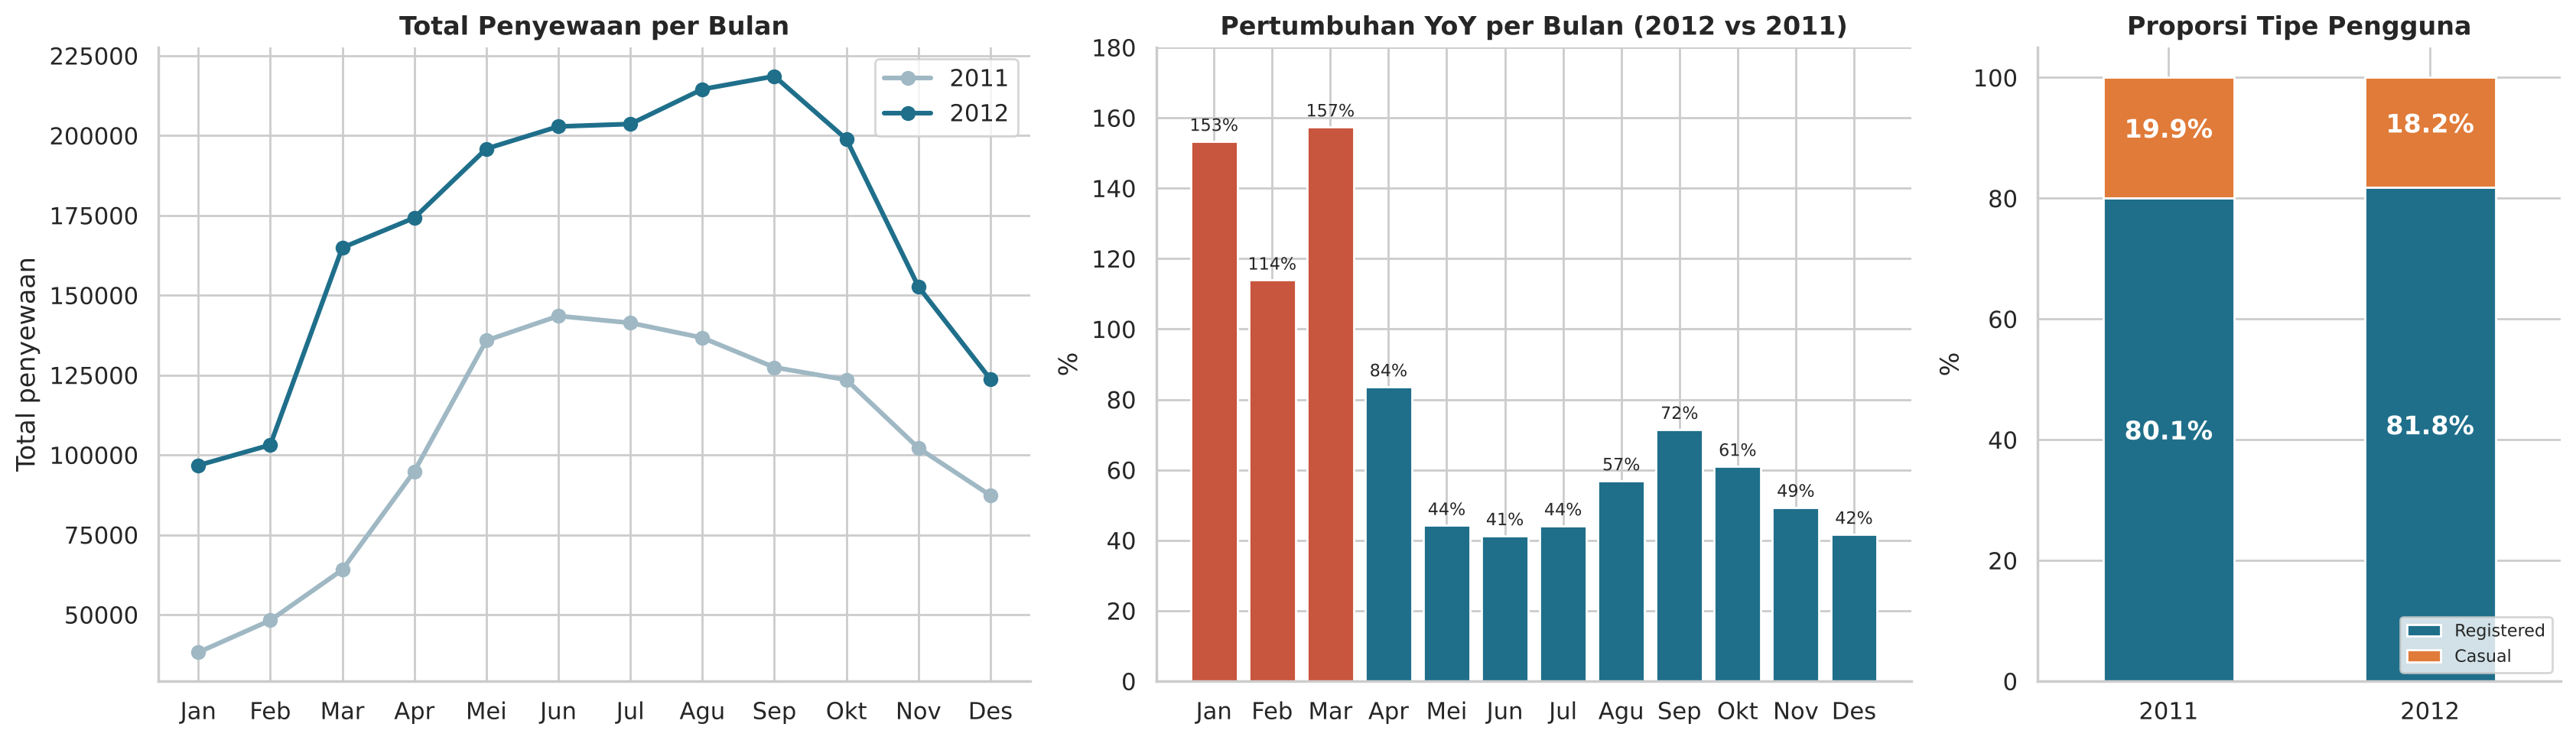

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 1.3, 0.9]})

# (a) tren bulanan
axes[0].plot(month_names, monthly[2011], marker="o", lw=2.2, color="#9fb8c4", label="2011")
axes[0].plot(month_names, monthly[2012], marker="o", lw=2.2, color="#1f6f8b", label="2012")
axes[0].set_title("Total Penyewaan per Bulan", weight="bold")
axes[0].set_ylabel("Total penyewaan")
axes[0].legend()

# (b) YoY
yoy = monthly["yoy_%"]
bars = axes[1].bar(month_names, yoy, color=["#c8553d" if v >= 100 else "#1f6f8b" for v in yoy])
for b, v in zip(bars, yoy):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 3, f"{v:.0f}%", ha="center", fontsize=8)
axes[1].set_title("Pertumbuhan YoY per Bulan (2012 vs 2011)", weight="bold")
axes[1].set_ylabel("%")
axes[1].set_ylim(0, 180)

# (c) proporsi pengguna
share = tot[["registered_%", "casual_%"]]
share.index = share.index.astype(str)
share.plot(kind="bar", stacked=True, ax=axes[2], color=["#1f6f8b", "#e07b39"], rot=0)
for i, (idx, r) in enumerate(share.iterrows()):
    axes[2].text(i, r["registered_%"] / 2, f"{r['registered_%']:.1f}%", ha="center", color="white", weight="bold")
    axes[2].text(i, r["registered_%"] + r["casual_%"] / 2, f"{r['casual_%']:.1f}%", ha="center", color="white", weight="bold")
axes[2].set_title("Proporsi Tipe Pengguna", weight="bold")
axes[2].set_ylabel("%")
axes[2].set_xlabel("")
axes[2].legend(["Registered", "Casual"], loc="lower right", fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 3**
- Total penyewaan naik **≈ 64,9%** dari 1,24 juta (2011) menjadi 2,05 juta (2012). Pertumbuhan YoY terbesar terjadi di **Maret (≈ 157%)** dan **Januari (≈ 153%)**, lalu melambat menjadi **≈ 41–44%** pada Mei–Juli dan Desember. Perlambatan ini wajar karena basis 2011 sudah tumbuh.
- Pengguna **registered** mendominasi: **≈ 80,1% (2011)** dan **≈ 81,8% (2012)**. Pengguna casual tumbuh **≈ 50,8%**, lebih lambat daripada registered (**≈ 68,4%**).

## Analisis Lanjutan (Opsional)

                 mean  count
kategori_suhu               
<10°C          1678.0     60
10–20°C        3692.0    299
20–30°C        5662.0    300
>30°C          5410.0     72


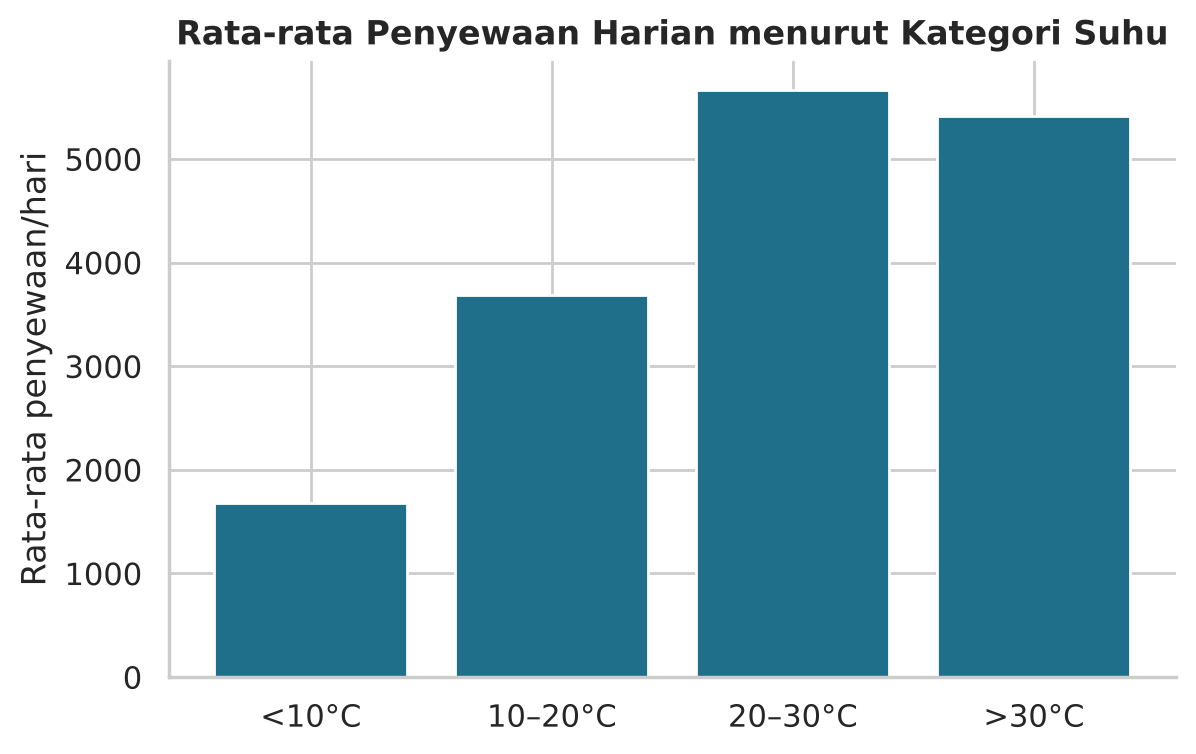

In [20]:
# Segmentasi sederhana (binning) suhu -> rata-rata penyewaan harian
day_clean["kategori_suhu"] = pd.cut(day_clean["temp_c"], bins=[0, 10, 20, 30, 40],
                                    labels=["<10°C", "10–20°C", "20–30°C", ">30°C"])
temp_seg = day_clean.groupby("kategori_suhu", observed=True)["cnt"].agg(["mean", "count"]).round(0)
print(temp_seg)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(temp_seg.index.astype(str), temp_seg["mean"], color="#1f6f8b")
ax.set_title("Rata-rata Penyewaan Harian menurut Kategori Suhu", weight="bold")
ax.set_ylabel("Rata-rata penyewaan/hari")
sns.despine()
plt.show()

Penyewaan harian meningkat bersama suhu hingga rentang 20–30°C, dan melemah saat suhu >30°C. Ini mendukung temuan bahwa musim semi/dingin dan cuaca buruk menekan permintaan.

## Conclusion

- **Kesimpulan Pertanyaan 1:** Permintaan per jam sangat bergantung pada tipe hari. Hari kerja memiliki dua puncak komuter (08:00 ≈ 605/jam dan 17:00 ≈ 656/jam), sedangkan hari non-kerja memiliki satu puncak rekreasi di sekitar 13:00 (≈ 459/jam). Pada dini hari (03:00–05:00) penyewaan nyaris nol di kedua tipe hari.
- **Kesimpulan Pertanyaan 2:** Cuaca hujan/salju ringan menurunkan rata-rata penyewaan harian ≈ 63% dan cuaca berkabut ≈ 17% dibanding cuaca cerah. Musim gugur adalah musim tersibuk (≈ 5.644/hari) dan musim semi terendah (≈ 2.604/hari), selisih ≈ 54%.
- **Kesimpulan Pertanyaan 3:** Penyewaan tumbuh ≈ 64,9% dari 2011 ke 2012 (YoY bulanan 41%–157%), didominasi pengguna registered (≈ 82% pada 2012) yang tumbuh lebih cepat daripada pengguna casual.

### Rekomendasi (Action Items)
1. **Redistribusi sepeda berbasis jam:** jadwalkan rebalancing armada pada hari kerja sebelum 07:00 dan sebelum 16:00 (menjelang puncak 08:00 dan 17:00), dan lakukan perawatan armada pada 00:00–05:00 dan 10:00–15:00 hari kerja saat permintaan rendah. Pada akhir pekan, siapkan sepeda ekstra di area wisata/taman pukul 11:00–16:00.
2. **Strategi musiman & cuaca:** adakan promosi/diskon pada musim semi dan hari berkabut untuk menaikkan permintaan, serta tawarkan paket langganan musim gugur–panas. Gunakan prakiraan cuaca untuk mengurangi armada yang disiagakan pada hari hujan/salju (permintaan turun ±63%) dan manfaatkannya untuk perawatan terjadwal.
3. **Pertumbuhan pengguna:** pertahankan basis registered (≈ 82%) lewat program loyalitas, dan tingkatkan konversi pengguna casual (yang pertumbuhannya lebih lambat) menjadi anggota dengan penawaran akhir pekan saat penyewaan casual tertinggi (≈ 1.371 per hari non-kerja vs ≈ 607 per hari kerja).